# Descriptive statistics of existing performance evidence

## Module 1. Data inventory and effective observation counts

**Scope:** This notebook currently implements Module 1 only. It inventories the current trajectory and describes metric availability without replaying pipelines, running profilers, or implementing optimizations. All outputs are separate from the bottleneck analysis.

**Units:** Pipelines are the primary observational units. Category rows and source-line records are nested within pipelines and are not independent experiments. Profiles, traces, execution summaries and predictions originate from potentially separate runs.

**Definitions:** A valid numeric value is finite. Missing values, non-numeric/infinite values and finite zero values are counted separately. Zero is a subset of valid numeric values, not a separate denominator. A zero CPU sample does not establish zero execution cost; unresolved line time is retained as missing. Coverage percentages describe records, not the percentage of runtime captured.

### Environment setup

Import libraries and configure plotting. No evidence files are read in this cell.


In [3]:
from pathlib import Path
import ast
import csv
import hashlib
import json
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'deai-matplotlib'))
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
get_ipython().run_line_magic('matplotlib', 'inline')


### Trajectory and analysis scope

Set paths, load the manifest, and validate unique pipeline IDs. Initialize the output collections.


In [4]:
root = Path.cwd().resolve()
trajectory = 'spaceship_titanic_students'
manifest_path = root / trajectory / 'trajectory.json'
output = root / 'results' / trajectory / 'descriptive_statistics'
figures, tables = {}, {}
pd.set_option('display.max_colwidth', 100)

manifest = json.loads(manifest_path.read_text())
steps = {Path(p['file']).stem: s['step'] for s in manifest['steps'] for p in s['pipelines']}
assert len(steps) == sum(len(s['pipelines']) for s in manifest['steps'])


### Expected evidence files

Build the expected file list from manifest pipelines and the shared input files.


In [5]:
expected = [('Manifest', manifest_path, None),
            ('Category summary', root / 'results' / trajectory / 'categories.csv', None),
            ('Execution summary', root / trajectory / 'results/summary.json', None),
            ('Runner source', root / trajectory / 'run_trajectory.py', None)]
for pipeline in steps:
    expected.extend([
        ('Profile', root / 'profiles' / trajectory / f'{pipeline}.json', pipeline),
        ('Trace', root / 'libraries' / trajectory / f'{pipeline}.json', pipeline),
        ('Pipeline source', root / trajectory / f'{pipeline}.py', pipeline),
        ('OOF predictions', root / trajectory / 'results' / pipeline / 'oof_predictions.csv', pipeline),
        ('Test probabilities', root / trajectory / 'results' / pipeline / 'test_probabilities.csv', pipeline),
    ])
for name in ['train.csv', 'test.csv', 'sample_submission.csv']:
    expected.append(('Input data', root / trajectory / 'input' / name, None))


### Input integrity snapshot

Hash existing inputs before analysis so the final checks can verify that they were not modified.


In [6]:
input_hashes = {str(path.relative_to(root)): hashlib.sha256(path.read_bytes()).hexdigest()
                for _, path, _ in expected if path.is_file()}


### Observed file inventory

Check file presence and inspect CSV headers and row counts. Display input-data dimensions and any missing files.


In [7]:
rows = []
for kind, path, pipeline in expected:
    count, columns = None, ''
    if path.is_file() and path.suffix == '.csv':
        with path.open(newline='') as handle:
            reader = csv.reader(handle)
            header = next(reader, [])
            columns = ', '.join(header)
            count = sum(1 for _ in reader)
    rows.append(dict(kind=kind, pipeline=pipeline, path=str(path.relative_to(root)),
                     present=path.is_file(), csv_rows=count, csv_columns=columns))
file_inventory = pd.DataFrame(rows)
display(file_inventory[file_inventory.kind.eq('Input data')][['path','present','csv_rows','csv_columns']])
if not file_inventory.present.all():
    display(file_inventory[~file_inventory.present][['kind','pipeline','path']])


,path,present,csv_rows,csv_columns
129,spaceship_titanic_students/input/train.csv,True,8693.0,"PassengerId, HomePlanet, CryoSleep, Cabin, Destination, Age, VIP, RoomService, FoodCourt, Shoppi..."
130,spaceship_titanic_students/input/test.csv,True,4277.0,"PassengerId, HomePlanet, CryoSleep, Cabin, Destination, Age, VIP, RoomService, FoodCourt, Shoppi..."
131,spaceship_titanic_students/input/sample_submission.csv,True,4277.0,"PassengerId, Transported"


### File coverage summary

Count expected, present and missing files by evidence type; compute the presence fraction.


In [6]:
file_coverage = file_inventory.groupby('kind', sort=False).agg(expected=('path','size'), present=('present','sum'))
file_coverage['missing'] = file_coverage.expected-file_coverage.present
file_coverage['present_fraction'] = file_coverage.present/file_coverage.expected
display(file_coverage.reset_index())


,kind,expected,present,missing,present_fraction
0,Manifest,1,1,0,1.0
1,Category summary,1,1,0,1.0
2,Execution summary,1,1,0,1.0
3,Runner source,1,1,0,1.0
4,Profile,25,25,0,1.0
5,Trace,25,25,0,1.0
6,Pipeline source,25,25,0,1.0
7,OOF predictions,25,25,0,1.0
8,Test probabilities,25,25,0,1.0
9,Input data,3,3,0,1.0


### Pipeline counts by step

Count the primary observational units in each manifest step and display their names.


In [7]:
step_sizes = pd.DataFrame([dict(step=s['step'], name=s.get('name',''), pipelines=len(s['pipelines'])) for s in manifest['steps']])
display(step_sizes)


,step,name,pipelines
0,1,Linear baselines,3
1,2,Domain feature additions,3
2,3,Feature ablations,3
3,4,CPU histogram boosting,5
4,5,CPU random forests,4
5,6,Fixed probability blends,4
6,7,Decision threshold sensitivity,3


### File and step coverage charts

Plot file availability and per-step pipeline counts from the preceding summary tables.


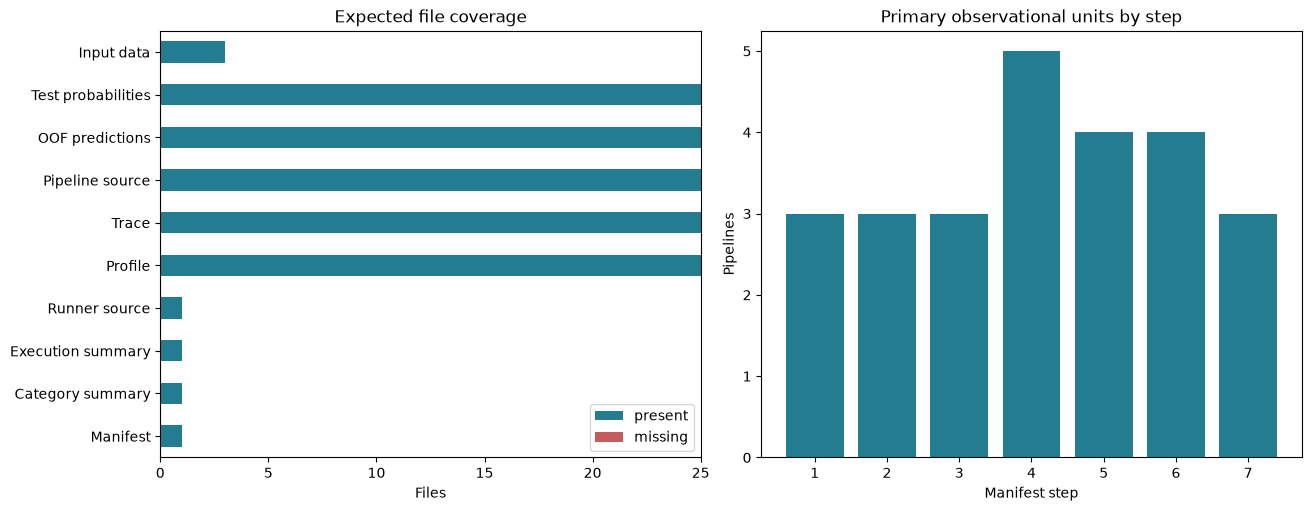

In [8]:
fig, axes = plt.subplots(1,2,figsize=(13,5),layout='constrained')
file_coverage[['present','missing']].plot.barh(stacked=True,ax=axes[0],color=['#247c91','#c65b5b'])
axes[0].set_xlabel('Files');axes[0].set_ylabel('');axes[0].set_title('Expected file coverage')
axes[1].bar(step_sizes.step,step_sizes.pipelines,color='#247c91')
axes[1].set_xticks(step_sizes.step);axes[1].set_xlabel('Manifest step');axes[1].set_ylabel('Pipelines')
axes[1].set_title('Primary observational units by step')
figures['file_and_step_coverage']=fig
display(fig);plt.close(fig)


### 1.1. Numeric metric availability

Metrics are summarized separately at pipeline, category-row and profile-line levels. Column presence is checked before numeric conversion. Allocation and copy-rate zeros are recorded values; their semantic validity has not been audited. The raw copy rate is not integrated into a copied volume.

The derived `resolved_attribution_s` uses all three finite CPU components and a finite elapsed value, and is only populated when their sum is positive. It is a sampling-based attribution, not an independent line timer.

,unit,metric,records,valid,missing,invalid,zero,valid_nonzero,valid_fraction
0,Pipeline profile,elapsed_time_sec,25,25,0,0,0,25,1.000000
1,Pipeline profile,max_footprint_mb,25,25,0,0,0,25,1.000000
2,Expected pipeline-category row,total_s,100,100,0,0,2,98,1.000000
3,Expected pipeline-category row,share_of_runtime,100,100,0,0,2,98,1.000000
4,Expected pipeline-category row,python_s,100,100,0,0,2,98,1.000000
5,Expected pipeline-category row,native_s,100,100,0,0,3,97,1.000000
6,Expected pipeline-category row,system_s,100,100,0,0,2,98,1.000000
7,Expected pipeline-category row,core_utilization,100,100,0,0,2,98,1.000000
8,Expected pipeline-category row,malloc_mb,100,100,0,0,8,92,1.000000
9,Expected pipeline-category row,n_mallocs,100,100,0,0,100,0,1.000000


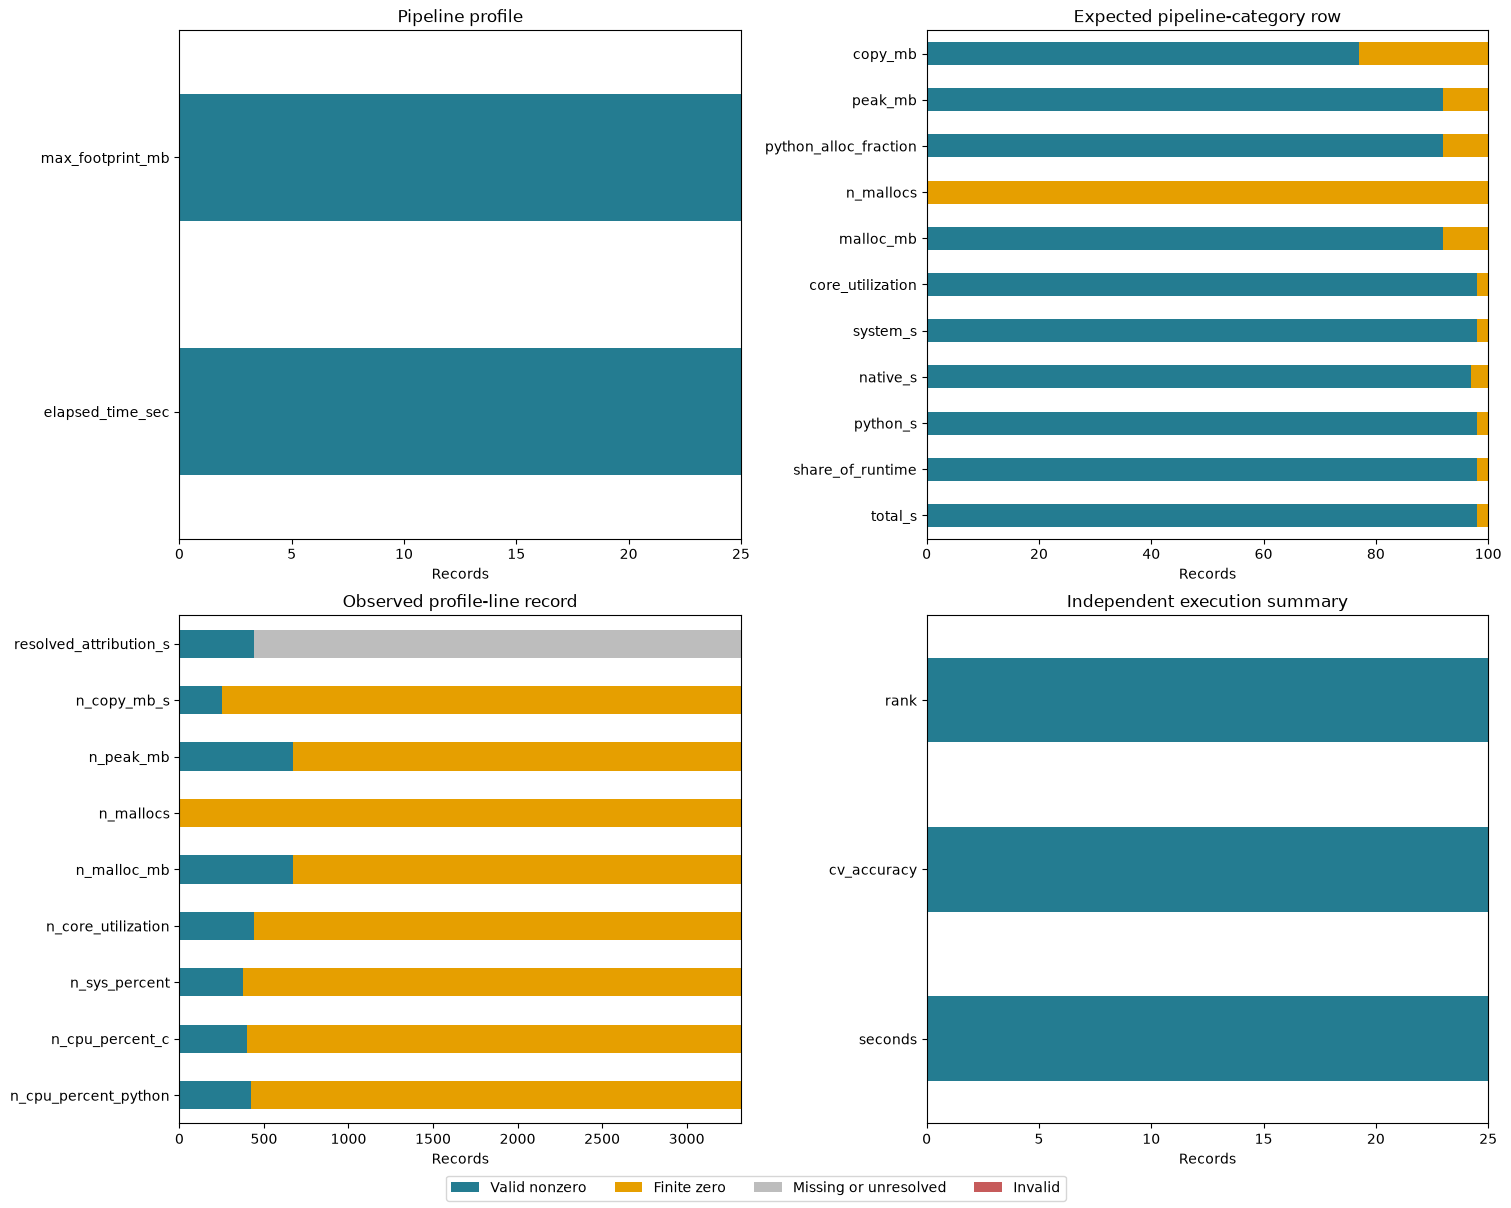

In [9]:
def metric_availability(frame, metrics, unit):
    records = []
    for metric in metrics:
        raw = frame[metric] if metric in frame else pd.Series(np.nan, index=frame.index)
        numeric = pd.to_numeric(raw, errors='coerce')
        finite = numeric.notna() & np.isfinite(numeric)
        missing = raw.isna()
        records.append(dict(unit=unit, metric=metric, records=len(raw), valid=int(finite.sum()),
                            missing=int(missing.sum()), invalid=int((~missing & ~finite).sum()),
                            zero=int((finite & numeric.eq(0)).sum()),
                            valid_nonzero=int((finite & numeric.ne(0)).sum()),
                            valid_fraction=float(finite.mean()) if len(raw) else np.nan))
    return pd.DataFrame(records)

pipeline_rows, line_rows, trace_only_rows = [], [], []
cpu_fields = ['n_cpu_percent_python','n_cpu_percent_c','n_sys_percent']
line_metrics = cpu_fields+['n_core_utilization','n_malloc_mb','n_mallocs','n_peak_mb','n_copy_mb_s']
for pipeline, step in steps.items():
    profile_path = root / 'profiles' / trajectory / f'{pipeline}.json'
    trace_path = root / 'libraries' / trajectory / f'{pipeline}.json'
    profile = json.loads(profile_path.read_text()) if profile_path.is_file() else {}
    trace = json.loads(trace_path.read_text()).get('lines',{}) if trace_path.is_file() else {}
    elapsed = profile.get('elapsed_time_sec',np.nan)
    pipeline_rows.append(dict(pipeline=pipeline, step=step, profile_present=bool(profile),
                              elapsed_time_sec=elapsed, max_footprint_mb=profile.get('max_footprint_mb',np.nan)))
    main_lines, seen = set(), set()
    for filename, detail in profile.get('files',{}).items():
        for record in detail.get('lines',[]):
            line = record['lineno']
            assert (filename,line) not in seen, 'Duplicate source-line profile record'
            seen.add((filename,line))
            is_main = filename == profile.get('program')
            if is_main: main_lines.add(line)
            has_trace = is_main and bool(trace.get(str(line)))
            components = pd.to_numeric(pd.Series([record.get(k,np.nan) for k in cpu_fields]),errors='coerce')
            finite_components = np.isfinite(components).all()
            elapsed_numeric = pd.to_numeric(pd.Series([elapsed]),errors='coerce').iloc[0]
            value = components.sum()*elapsed_numeric/100 if finite_components and np.isfinite(elapsed_numeric) else np.nan
            sampled = pd.notna(value) and value>0
            state = 'Time sampled' if sampled else 'Separate trace call only' if has_trace else 'Other unresolved'
            line_rows.append(dict(pipeline=pipeline, step=step, profile_source=filename, line=line,
                                  evidence_status=state, resolved_attribution_s=value if sampled else np.nan,
                                  **{k:record.get(k,np.nan) for k in line_metrics}))
    for line, modules in trace.items():
        if int(line) not in main_lines and modules:
            trace_only_rows.append(dict(pipeline=pipeline, step=step, profile_source='trace-only',
                                        line=int(line), evidence_status='Separate trace call only'))
pipelines = pd.DataFrame(pipeline_rows)
profile_lines = pd.DataFrame(line_rows,columns=['pipeline','step','profile_source','line','evidence_status','resolved_attribution_s']+line_metrics)
evidence_records = pd.concat([profile_lines[['pipeline','step','profile_source','line','evidence_status']],pd.DataFrame(trace_only_rows)],ignore_index=True)
category_metrics = ['total_s','share_of_runtime','python_s','native_s','system_s','core_utilization',
                    'malloc_mb','n_mallocs','python_alloc_fraction','peak_mb','copy_mb']
category_path = root / 'results' / trajectory / 'categories.csv'
categories_all = pd.read_csv(category_path) if category_path.is_file() else pd.DataFrame(columns=['pipeline','category']+category_metrics)
categories = categories_all[categories_all.pipeline.isin(steps)].copy()
assert not categories.duplicated(['pipeline','category']).any()
expected_category_rows = pd.MultiIndex.from_product([list(steps),['setup','data handling','models','other']],names=['pipeline','category'])
category_grid = categories.set_index(['pipeline','category']).reindex(expected_category_rows).reset_index()
execution_path = root / trajectory / 'results/summary.json'
execution = pd.DataFrame(json.loads(execution_path.read_text())) if execution_path.is_file() else pd.DataFrame(columns=['pipeline_id','seconds','cv_accuracy','rank'])
assert not execution.pipeline_id.duplicated().any()
execution_grid = execution.set_index('pipeline_id').reindex(list(steps)).reset_index()
availability = pd.concat([
    metric_availability(pipelines,['elapsed_time_sec','max_footprint_mb'],'Pipeline profile'),
    metric_availability(category_grid,category_metrics,'Expected pipeline-category row'),
    metric_availability(profile_lines,line_metrics+['resolved_attribution_s'],'Observed profile-line record'),
    metric_availability(execution_grid,['seconds','cv_accuracy','rank'],'Independent execution summary'),
],ignore_index=True)
display(availability)
fig, axes = plt.subplots(2,2,figsize=(15,12),layout='constrained')
for ax,(unit,group) in zip(axes.flat,availability.groupby('unit',sort=False)):
    group.set_index('metric')[['valid_nonzero','zero','missing','invalid']].plot.barh(
        stacked=True,ax=ax,color=['#247c91','#e69f00','#bdbdbd','#c65b5b'])
    ax.set_title(unit);ax.set_xlabel('Records');ax.set_ylabel('')
    ax.get_legend().remove()
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, ['Valid nonzero', 'Finite zero', 'Missing or unresolved', 'Invalid'], loc='outside lower center', ncol=4)
figures['metric_availability']=fig
display(fig);plt.close(fig)

### 1.2. Sampling and trace coverage

Each profile source-line record is counted once. Trace calls with no corresponding main-file profile record are added separately. A trace call at the same line number is only a cross-file indexing clue: it does not prove matching source versions or execution identity. Profiles can also contain records from internal files. No-time records remain unresolved, even when every raw CPU component is zero.

,measure,count
0,Manifest pipelines,25
1,Manifest steps,7
2,Existing category rows in scope,100
3,Expected category rows,100
4,Profile source-line records,3321
5,Additional trace-only records,0
6,Time-sampled records,441
7,Separate-trace-only evidence records,1885
8,Other unresolved records,995


evidence_status,Time sampled,Separate trace call only,Other unresolved
step,,,
1,37,211,97
2,57,205,114
3,39,223,117
4,73,367,205
5,64,285,163
6,101,328,170
7,70,266,129


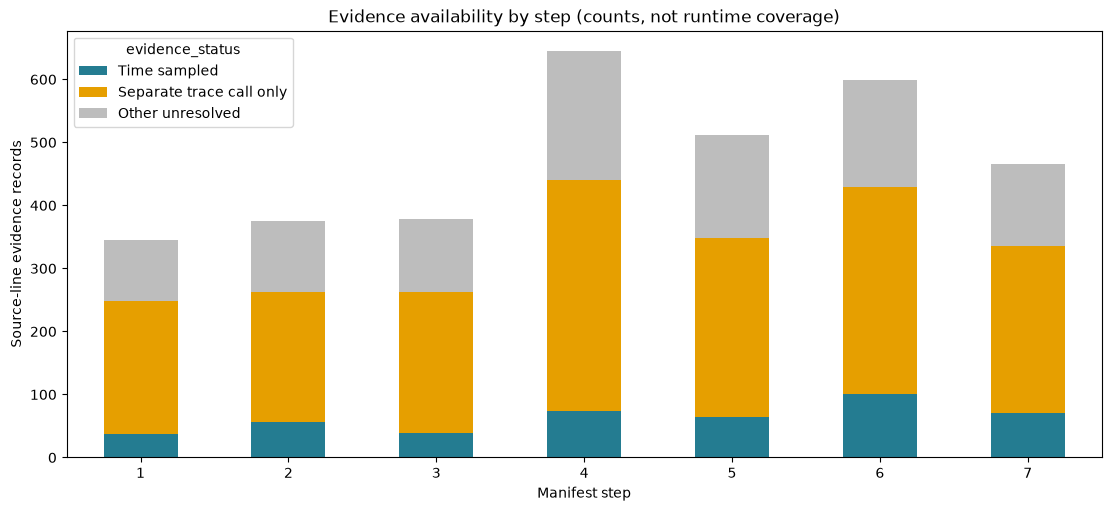

In [10]:
status_order=['Time sampled','Separate trace call only','Other unresolved']
sampling_coverage = pd.crosstab(evidence_records.pipeline,evidence_records.evidence_status).reindex(index=list(steps),columns=status_order,fill_value=0)
sampling_coverage['step'] = sampling_coverage.index.map(steps)
coverage_by_step = sampling_coverage.groupby('step')[status_order].sum()
record_counts = pd.DataFrame([
    ('Manifest pipelines',len(steps)),('Manifest steps',len(manifest['steps'])),
    ('Existing category rows in scope',len(categories)),('Expected category rows',len(category_grid)),
    ('Profile source-line records',len(profile_lines)),('Additional trace-only records',len(trace_only_rows)),
    ('Time-sampled records',int(evidence_records.evidence_status.eq('Time sampled').sum())),
    ('Separate-trace-only evidence records',int(evidence_records.evidence_status.eq('Separate trace call only').sum())),
    ('Other unresolved records',int(evidence_records.evidence_status.eq('Other unresolved').sum())),
],columns=['measure','count'])
display(record_counts)
display(coverage_by_step)
fig,ax=plt.subplots(figsize=(11,5),layout='constrained')
coverage_by_step.plot.bar(stacked=True,ax=ax,color=['#247c91','#e69f00','#bdbdbd'])
ax.set_xlabel('Manifest step');ax.set_ylabel('Source-line evidence records')
ax.set_title('Evidence availability by step (counts, not runtime coverage)')
ax.tick_params(axis='x',rotation=0)
figures['sampling_coverage']=fig
display(fig);plt.close(fig)

### 1.3. Export and verification

Export only Module 1 tables and figures. Numeric count partitions and evidence counts must balance. Input hashes verify that this notebook has not changed its source files. These checks validate the analysis implementation, not the accuracy of the original profiling measurements.

In [11]:
assert (availability.valid+availability.missing+availability.invalid == availability.records).all()
assert (availability.valid_nonzero+availability.zero == availability.valid).all()
assert coverage_by_step.to_numpy().sum() == len(evidence_records)
assert profile_lines.resolved_attribution_s.notna().sum() == evidence_records.evidence_status.eq('Time sampled').sum()
assert not evidence_records.duplicated(['pipeline','profile_source','line']).any()
assert all(hashlib.sha256((root/path).read_bytes()).hexdigest()==digest for path,digest in input_hashes.items())
# Exercise missing, zero, nonnumeric and infinite-value handling explicitly.
probe=metric_availability(pd.DataFrame({'x':[0,1,None,'invalid',np.inf]}),['x'],'test').iloc[0]
assert (probe.valid,probe.zero,probe.missing,probe.invalid)==(2,1,1,2)
assert metric_availability(pd.DataFrame(index=range(3)),['absent'],'test').iloc[0].missing==3

tables = {'file_inventory':file_inventory, 'file_coverage':file_coverage.reset_index(),
          'step_sizes':step_sizes, 'record_counts':record_counts, 'metric_availability':availability,
          'sampling_coverage':sampling_coverage.reset_index(), 'coverage_by_step':coverage_by_step.reset_index()}
output.mkdir(parents=True,exist_ok=True)
for name,table in tables.items():table.to_csv(output/f'{name}.csv',index=False)
for name,figure in figures.items():figure.savefig(output/f'{name}.png',dpi=150)
print(f'Module 1 complete: {len(tables)} tables and {len(figures)} figures exported to {output}.')
review_notebook = json.loads((root/'descriptive_statistics.ipynb').read_text())
review_fingerprint = hashlib.sha256(json.dumps({
    'inputs':input_hashes,
    'code':[''.join(c['source']) for c in review_notebook['cells'] if c['cell_type']=='code'],
},sort_keys=True).encode()).hexdigest()
display(Markdown('**Review status:** Current evidence and code match the reviewed snapshot.'
    if review_fingerprint==review_notebook.get('metadata',{}).get('evidence_review',{}).get('fingerprint')
    else '**STALE REVIEW:** Evidence or code changed; refresh the assistant-written interpretation.'))


Module 1 complete: 7 tables and 3 figures exported to /Users/tue/Documents/10_Projects/deai-pro/results/spaceship_titanic_students/descriptive_statistics.


**Review status:** Current evidence and code match the reviewed snapshot.

### Reviewed interpretation of Module 1

Reviewed on 2026-11-05 after executing the notebook and inspecting its tables and chart images. This prose is assistant-written and is not automatically regenerated on execution.

- **File coverage is complete for the expected inventory.** The trajectory contains 25 pipelines across seven steps, with 3, 3, 3, 5, 4, 4 and 3 candidates respectively. All 25 profiles, 25 traces, 25 pipeline sources and 50 prediction files are present. The category summary contains all 100 expected pipeline-category rows. File presence does not prove provenance or semantic validity.
- **Pipeline-level descriptive statistics are feasible.** Profile elapsed time and process peak memory each have 25 finite, nonzero observations. The independent execution summary also contains 25 finite values for time, accuracy and rank; these must remain separate from profile timing.
- **Raw numeric completeness is not sampling completeness.** The inspected raw profile-line metrics all contain finite values, but many are zero. Of 3,321 profile source-line records, 441 (13.28% of records) have positive sampled time. The remaining 2,880 have unresolved time: 1,885 have a call observed in the separate trace and 995 have no such call evidence. There are no additional trace-only line records outside the profile main-file line inventory. The 13.28% figure is not a runtime-coverage estimate or a success rate.
- **Some recorded metrics need special caution.** Allocation counts (`n_mallocs`) are zero in all 3,321 profile records and all 100 category rows. These values cannot support a meaningful ranking of allocation counts, and they do not establish that no allocations occurred. Two category rows have zero attributed time; these are retained as recorded summary values without interpreting the underlying operations as free. Copy-rate fields and the existing `copy_mb` summary remain unaudited.
- **The coverage chart reflects record counts.** Steps with more candidates or more source lines naturally contribute more records. Differences in these bars do not establish relative profiler accuracy, execution efficiency or independent sample sizes.

The verified outputs are seven CSV tables and three figures. Input hashes were unchanged, all count partitions balance, and missing/zero/non-numeric/infinite-value cases passed explicit checks. Modules 2–6 have not been implemented.
